### Stationarity in Time Series

**What Is a Stationary Time Series?** <br>
A stationary time series is a type of time series whose statistical properties do not change over time

1. Constant Mean The expected value of the series is constant and does not depend on time
$$ E[X_{t}]=\mu \ $$
2. Constant Variance The variance of the series is constant, finite, and does not change over time.
    $$ Var(X_{t})=E[(X_{t}-\mu )^{2}]=\sigma ^{2}\ $$
3. Constant Covariance (Autocovariance) The covariance between two observations depends only on the distance (lag \(k\)) between them, not the specific point in time
    $$ Cov(X_{t},X_{t+k})=E[(X_{t}-\mu )(X_{t+k}-\mu )]=\gamma _{k} $$

### Exercise 

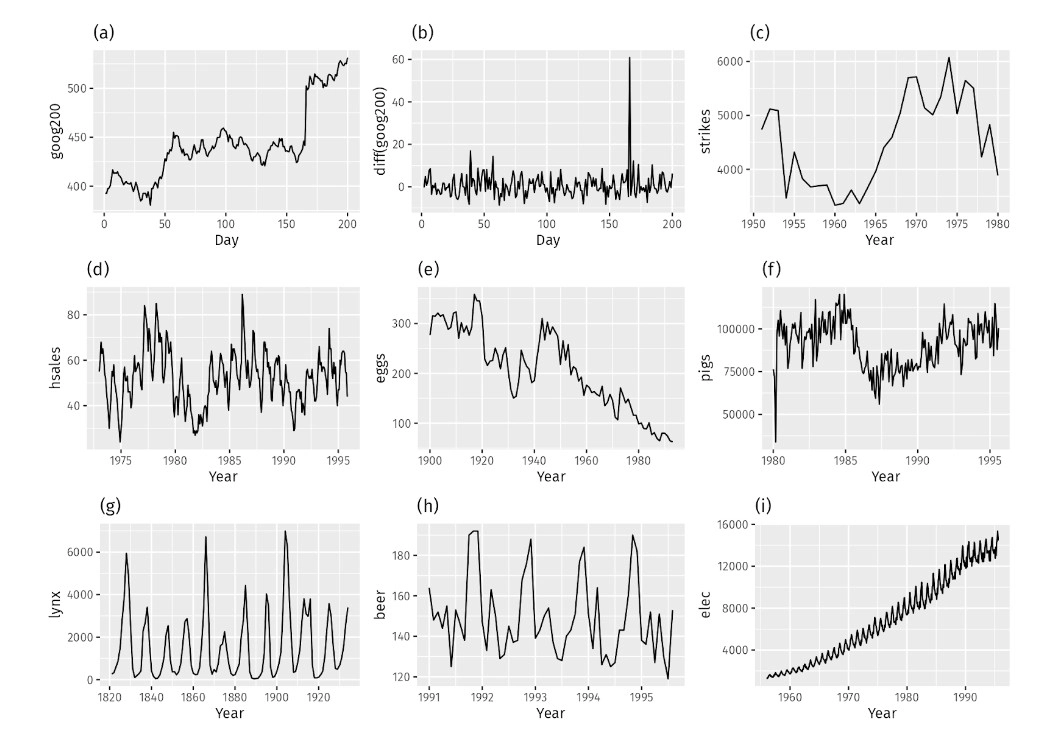

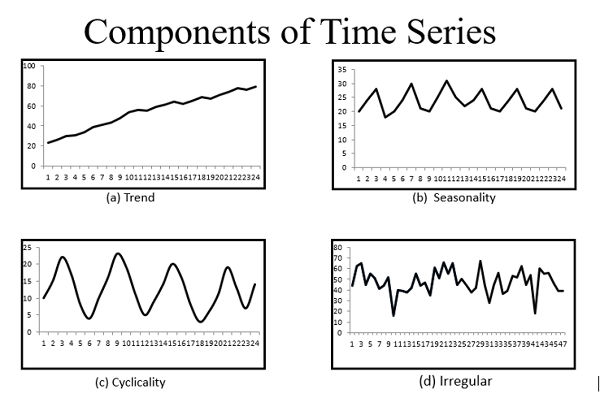


**Components** <br>
Intercept  <br>
Trend   <br>
Seasonality  <br>
Cycle   <br>

### DS and TS

**Trend Stationary (TS) series fluctuate around a deterministic trend, with shocks having temporary effects** <br>
$$y_{t}=\alpha +\beta t+\epsilon _{t}\ $$

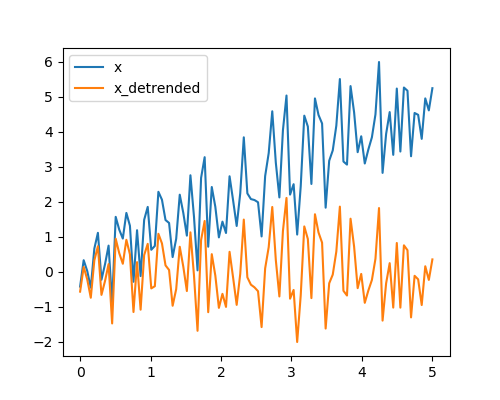


**Example**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

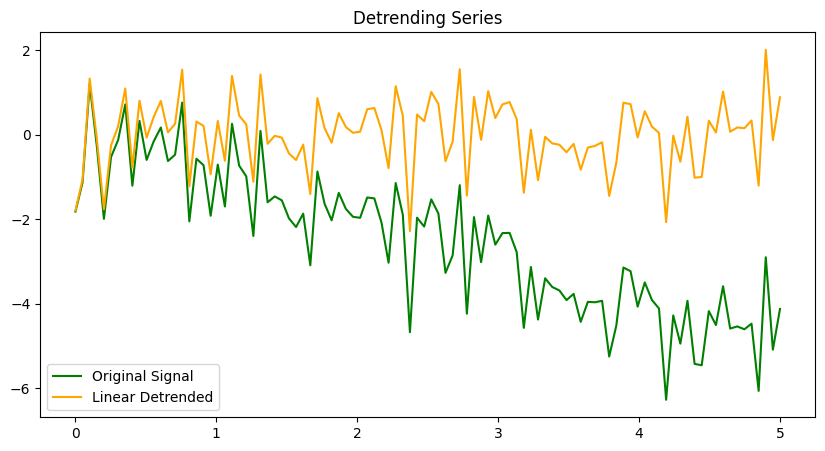

In [2]:
t = np.linspace(0, 5, 100)
b = t*-1
x = b + np.random.normal(size=100)

# Detrend the data
x_detrended_linear = signal.detrend(x, type="linear") 

plt.figure(figsize=(10, 5))
plt.plot(t, x, label="Original Signal", color = "green")
plt.plot(t, x_detrended_linear, label="Linear Detrended", color='orange')
plt.legend()
plt.title("Detrending Series")
plt.show()

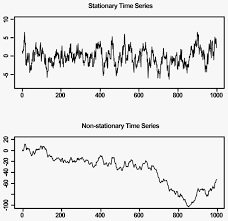

### DS

The most common form, used to remove a linear trend, is calculated by subtracting the previous observation from the current one: <br>
$$y_{t}^{\prime }=y_{t}-y_{t-1}\ $$

**Example**

In [4]:
import pandas as pd

In [5]:
url = "https://raw.githubusercontent.com/datasets/oil-prices/refs/heads/main/data/brent-monthly.csv"
oil_price = pd.read_csv(url)
print(oil_price.head())

         Date  Price
0  1987-05-15  18.58
1  1987-06-15  18.86
2  1987-07-15  19.86
3  1987-08-15  18.98
4  1987-09-15  18.31


In [6]:
oil_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 470 entries, 0 to 469
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    470 non-null    str    
 1   Price   470 non-null    float64
dtypes: float64(1), str(1)
memory usage: 7.5 KB


<Axes: >

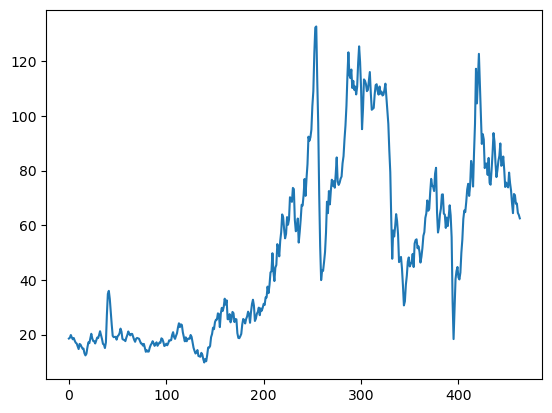

In [68]:
oil_price["Price"].plot()

In [69]:
oil_price["Date"] = pd.to_datetime(oil_price["Date"])

In [7]:
oil_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 470 entries, 0 to 469
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    470 non-null    str    
 1   Price   470 non-null    float64
dtypes: float64(1), str(1)
memory usage: 7.5 KB


In [71]:
oil_price.head()

,Date,Price
0,1987-05-15,18.58
1,1987-06-15,18.86
2,1987-07-15,19.86
3,1987-08-15,18.98
4,1987-09-15,18.31


In [72]:
oil_price.set_index("Date", inplace = True)

In [73]:
oil_price.head()

,Price
Date,
1987-05-15,18.58
1987-06-15,18.86
1987-07-15,19.86
1987-08-15,18.98
1987-09-15,18.31


<Axes: xlabel='Date'>

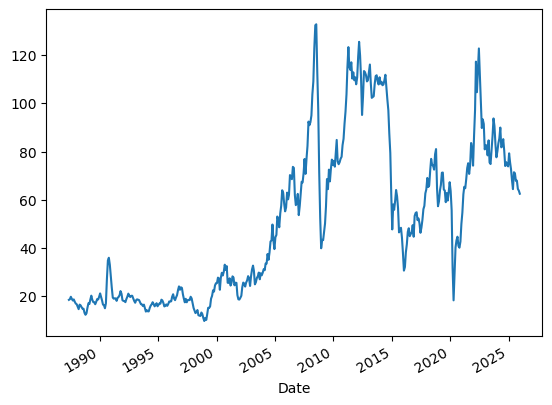

In [74]:
oil_price["Price"].plot()

ADF, KPSS, Philips Perron

In [8]:
from statsmodels.tsa.stattools import adfuller

In [9]:
def adf_test(series):
    result = adfuller(series)
    print(result)
    print("ADF Statistics: {}".format(result[0]))
    print("p- value: {}".format(result[1]))
    if result[1] <= 0.05:
        print("strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary")
    else:
        print("weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary ")

In [78]:
adf_test(oil_price["Price"])

(np.float64(-2.379504822242869), np.float64(0.14760476821873764), 1, 462, {'1%': np.float64(-3.444583778100581), '5%': np.float64(-2.8678163032301995), '10%': np.float64(-2.570113030490433)}, np.float64(2667.7653434013655))
ADF Statistics: -2.379504822242869
p- value: 0.14760476821873764
weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary 


## Use Techniques Differencing
## Method01
oil_price["Price"] - oil_price["Price]-1 <br>
    Yt - Yt-1

In [79]:
oil_price["oil price First Diff"] = oil_price["Price"]-oil_price["Price"].shift(1)
print(oil_price.head())

            Price  oil price First Diff
Date                                   
1987-05-15  18.58                   NaN
1987-06-15  18.86                  0.28
1987-07-15  19.86                  1.00
1987-08-15  18.98                 -0.88
1987-09-15  18.31                 -0.67


In [82]:
adf_test(oil_price["oil price First Diff"].dropna())

(np.float64(-9.783319301547422), np.float64(6.643891556929069e-17), 5, 457, {'1%': np.float64(-3.444740396477859), '5%': np.float64(-2.8678852001919073), '10%': np.float64(-2.570149751878151)}, np.float64(2665.2205486632847))
ADF Statistics: -9.783319301547422
p- value: 6.643891556929069e-17
strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary


In [ ]:
#Method 2

In [83]:
oil_price["oil price First Diff_using Diff"] = oil_price["Price"].diff(1)
oil_price.head()

,Price,oil price First Diff,oil price First Diff_using Diff
Date,,,
1987-05-15,18.58,NaN,NaN
1987-06-15,18.86,0.28,0.28
1987-07-15,19.86,1.00,1.00
1987-08-15,18.98,-0.88,-0.88
1987-09-15,18.31,-0.67,-0.67


### White_noise

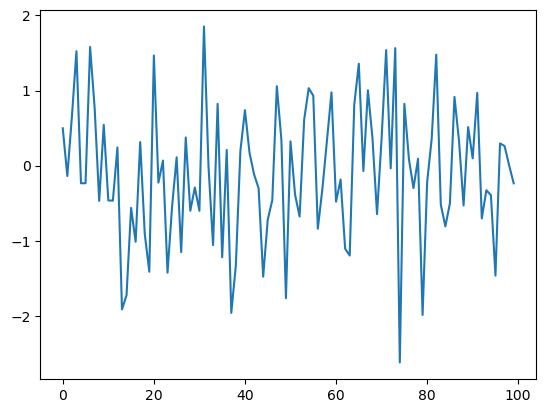

In [84]:
np.random.seed(42)
n = 100
t = np.arange(n)
white_noise = np.random.normal(0,1,n)
plt.plot(white_noise)

1. Additive Model
$$
Y_t = T_t + S_t + E_t
$$

2. Multiplicative Model
$$
Y_t = T_t \times S_t \times E_t
$$